In [2]:
%matplotlib widget
import pandas as pd
import numpy as np
from plotting_params import use_my_style
import matplotlib.pyplot as plt
use_my_style()
from pathlib import Path
import astropy.constants as const
from scipy.ndimage import median_filter
from PyAstronomy.pyasl import instrBroadGaussFast
from itertools import product
from cross_correlation_mod import cross_correlate
from joblib import Parallel, delayed 
from astropy.io import fits


# 1) Load telluric-corrected spectrum (for 1 observation)

also, normalise flux and uncertainty

In [14]:
tel_corrected_file = "/home/alst3712/exocomet_project/clean_data/2022-04-05_M4368/order_regions/tellurics_corrected_version_0.8.3_2022-04-05_M4368_base.dat"
observed = pd.read_csv(tel_corrected_file, comment="#", names=["wavelength", "flux", "error"], delimiter=r"\s+")

wavelength=observed["wavelength"].to_numpy()
observed_flux=observed["flux"].to_numpy()
observed_error=observed["error"].to_numpy()

wavelength = wavelength / 1000 # convert nm to microns


#sort just in case
order = np.argsort(wavelength)
wavelength = wavelength[order]
observed_flux = observed_flux[order]
observed_error = observed_error[order]

norm_constant = np.nanmedian(observed_flux)
observed_flux_norm = observed_flux / norm_constant
observed_error_norm = observed_error / np.abs(norm_constant)
print(f' Flux norm factor is {norm_constant:.3e}')

dx = np.diff(wavelength)
typical_spacing = np.nanmedian(dx[dx > 0])

gap_indices = np.where(dx > 2 * typical_spacing)[0]

wavelength_plot = np.insert(wavelength, gap_indices + 1, np.nan)
flux_plot = np.insert(observed_flux_norm, gap_indices + 1, np.nan)
error_plot = np.insert(observed_error_norm, gap_indices + 1, np.nan)

min_wavelength_obs, max_wavelength_obs  = np.min(wavelength), np.max(wavelength)

 Flux norm factor is 3.868e+04


In [18]:
np.nanmedian(observed_flux/observed_error)

np.float64(46.88334818634341)

In [4]:
median_SNR = np.nanmedian(observed_flux_norm/observed_error_norm)
print(f'The median SNR is {median_SNR:.2f}')
# def shifted_model(v):
#     return np.interp(wavelength / (1 + v / const.c.to('km/s').value), wavelength, observed_flux_norm)

The median SNR is 47.47


# 2) Load one of the CO cross-section CSVs (for 1 temperature)

In [ ]:
# model_file = Path('/home/alst3712/exocomet_project/Opacity_spectra/data/processed/CO_T100K.csv')
# temperature = int(model_file.stem.split('T')[1].replace('K', ''))

#model_files = [f'/home/alst3712/exocomet_project/Opacity_spectra/data/processed/CO_T{t}K.csv' for t in temperatures]
allowed_temps = [10, 100, 300, 400, 1000]

def load_co_model(temp):
        """
        Parameters
        ----------
        temp : int
                Temperature in K. Allowed values: 10, 10, 100, 300, 400, 1000.

        Return
        ------
        model_wavelength and cross_section arrays
        """
        allowed_temps = [0, 10, 100, 300, 400, 1000]

        if temp not in allowed_temps:
                raise ValueError(f"temp must be one of {allowed_temps} K.")
        
        model_file = f'/home/alst3712/exocomet_project/Opacity_spectra/data/processed/CO_T{temp}K.csv'
        co_model = pd.read_csv(model_file)

        cross_section = co_model['cross_section_cm2_molecule'].to_numpy()
        model_wavelength = co_model['wavelength_um'].to_numpy()

        # again, make sure they are ordered:

        model_order = np.argsort(model_wavelength)
        model_wavelength = model_wavelength[model_order]
        cross_section = cross_section[model_order]

        ## only care about the wavelengths that the data has (took crires range):

        inside = ((model_wavelength >= 1) & 
                (model_wavelength <= 6))

        model_wavelength = model_wavelength[inside]
        cross_section = cross_section[inside]

        return model_wavelength, cross_section

In [5]:
wvl, crs = load_co_model(100)
plt.plot(wvl, crs)
plt.yscale('log')

# 3) Convert the cross-section into an absorption specrum

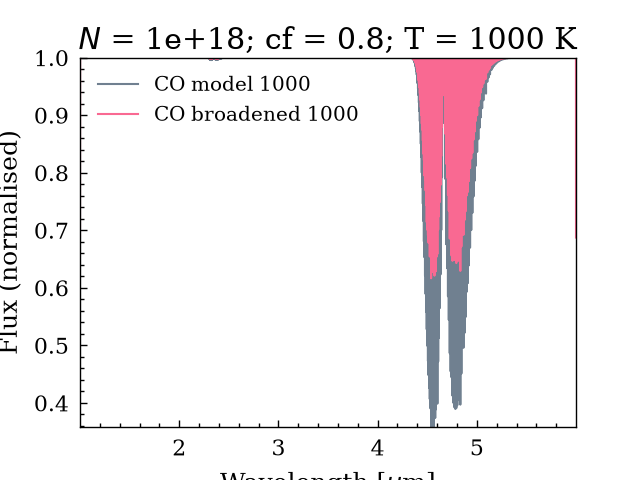

In [10]:
from itertools import product 

def make_co_template(temp, column_density, c_f):
    """
    Parameters
    ----------
    temp : int
        Temperature in K. Allowed values: 0, 10, 100, 300, 400, 1000.

    Return
    ------
    absorption, transmission, broadened arrays
    """

    if temp not in allowed_temps:
        raise ValueError(f"temp must be one of {allowed_temps} K.")
    
    # Optical depth:
    # tau = N_CO * sigma
    #
    # Units:
    # molecules/cm^2 * cm^2/molecule = dimensionless.

    model_wavelength, cross_section = load_co_model(temp)
    optical_depth = column_density * cross_section

    # Beer-Lambert law for pure absorption.

    # Partial covering:
    # a fraction f of the stellar continuum is covered by gas,
    # while the remaining fraction 1-f is unobscured.

    transmission = np.exp(-optical_depth)
    absorption = c_f * (1 - transmission)
    flux = 1 - absorption

    
    # use py astronomy to get intrumental broadening
    broadened = instrBroadGaussFast(model_wavelength, flux, resolution=10000, equid=True)

    return absorption, transmission, broadened


Ns = 1e15, 1e16, 1e17, 1e18
cfs = [0.3, 0.6, 0.9]

for T, N, cf in product(allowed_temps, Ns, cfs):

    model_wavelength, _ = load_co_model(T)
    _, _, broadened_model_flux = make_co_template(T, N, cf)
    example_model_df = pd.DataFrame({'wavelength':model_wavelength*1000, 'flux':broadened_model_flux,})
    output_file = Path(f'Opacity_spectra/CO_absorptions/CO_model_{T}K_{N:.0e}_{cf}cf.csv')
    if output_file.exists():
        continue
    else:
        example_model_df.to_csv(output_file)

# save for a range of column densities and cover fractions (and eventually temperatures by changing the model file)

column_density = 1e18

cover_fraction = 0.8
temp = 1000
abs, trans, broad = make_co_template(temp, column_density, cover_fraction)
model_wavelength, _ = load_co_model(temp)


fig, ax = plt.subplots()
plt.plot(model_wavelength, trans, c='slategrey', label='CO model 1000 ')
plt.plot(model_wavelength, broad, label='CO broadened 1000 ')
#plt.xlim(4.5, 4.52)
ax.ticklabel_format(useOffset=False)
#plt.ylim(0.999999, 1)
plt.ylabel('Flux (normalised)')
plt.xlabel(r'Wavelength [$\mu$m]')
plt.title(f'$N$ = {column_density:.0e}; cf = {cover_fraction}; T = {temp} K')
plt.legend()
plt.show()

# Add noise to the model

In [7]:
def make_noisy_template(broadened_original, SNR, rng):

    sigma = np.abs(broadened_original) / SNR
    
    noisy_flux = broadened_original + rng.normal(0, sigma)

    # FIT THE CONTINUUM FIRST  
    # coeff = np.polyfit(model_wavelength, noisy_flux, deg=3)
    # continuum = np.polyval(coeff, model_wavelength)
    # #fake_norm_const = np.median(noisy_flux)

    # normed_flux = noisy_flux/continuum

    return noisy_flux

rng = np.random.default_rng(10)

print(rng.normal(0, 10))
noisy_flux = make_noisy_template(broad, median_SNR, rng)
plt.plot(model_wavelength, noisy_flux, label='Added noise')
plt.plot(model_wavelength, broad, label='Original broadened CO')
plt.legend()
plt.ylabel('Flux (normalised)')
plt.xlabel(r'Wavelength [$\mu$m]')
plt.show()



-11.03338449065532


NameError: name 'broad' is not defined

# Add noise but following data's chunks

In [ ]:
median_SNR

np.float64(47.4671971098946)

In [ ]:
def make_noisy_template_chunks(temp, column_density, c_f, SNR, rng):

    model_wavelength, _ = load_co_model(temp)
    data_wavelength = wavelength
    
    _, _, tempflux = make_co_template(temp, column_density, c_f)

    noisyflux = make_noisy_template(tempflux, SNR, rng)

    noisyflux_chunked = np.interp(data_wavelength, model_wavelength, noisyflux)
    error = np.full_like(noisyflux_chunked, 1/SNR)

    return noisyflux_chunked, error


T, N, cf, SNR = 1000, 1e18, 0.8, median_SNR
noisy_flux, error_flux = make_noisy_template_chunks(T, N, cf, SNR, rng)

#Andrea's script needs nm
example_dat_df = pd.DataFrame({'wavelength': wavelength*1000,'flux': noisy_flux, 'error':error_flux})
example_dat_df.to_csv(f'fake_data_{T}K_{N}_{cf}cf_{SNR:.2f}SNR.dat')




dx = np.diff(wavelength)
typical_spacing = np.nanmedian(dx[dx > 0])

gap_indices = np.where(dx > 2 * typical_spacing)[0]

wavelength_plot = np.insert(wavelength, gap_indices + 1, np.nan)
noisy_flux_plot = np.insert(noisy_flux, gap_indices + 1, np.nan)


rng = np.random.default_rng(10)

plt.plot(model_wavelength, broad, label='Original broadened CO')
plt.plot(wavelength_plot, noisy_flux_plot, label='Added noise')

plt.legend()
plt.ylabel('Flux (normalised)')
plt.xlabel(r'Wavelength [$\mu$m]')
plt.title('Spectrum with wavelength in chunks')
plt.xlim(3.3, 5.4)
plt.show()

NameError: name 'median_SNR' is not defined

# Next: cross-correlate over a parameter space

## general ccf 

Text(0.5, 1.0, 'Cross-correlation function with chunked fake data')

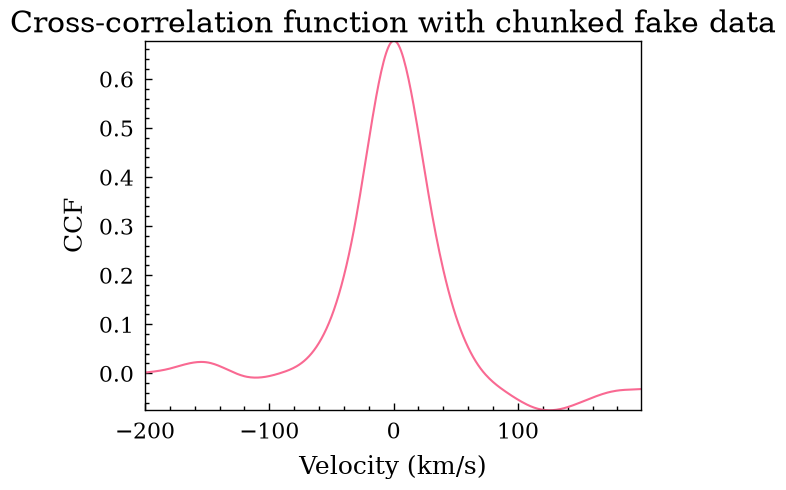

In [16]:
velocities = np.arange(-200, 200, 1)

def general_ccf(temp, column_density, c_f, SNR, rng):

    model_wavelength, _ = load_co_model(temp)
    _, _, tempflux = make_co_template(temp, column_density, c_f)

    #noisyflux = make_noisy_template(tempflux, SNR, rng)
    noisyflux, _ = make_noisy_template_chunks(temp, column_density, c_f, SNR, rng)

    #sort the fluxes
    index = np.argsort(wavelength)
    template_flux_added_noise = np.asarray(noisyflux)[index]

    index2 = np.argsort(model_wavelength)
    template_flux = np.asarray(tempflux)[index2]

    # need to convert to dfs
    noisy_df = pd.DataFrame({'wavelength': (wavelength*1000), 'flux': (template_flux_added_noise)}) #CONVERT TO NM!!
    template_df = pd.DataFrame({'wavelength': (model_wavelength*1000), 'flux': (template_flux)}) #CONVERT TO NM!!

    noisy_df = noisy_df[noisy_df['wavelength'].between(template_df['wavelength'].min() + 7 ,template_df['wavelength'].max() - 7)]
    

    ccf = cross_correlate(noisy_df, template_df, velocities)

    return ccf

rng = np.random.default_rng(10)
model_wavelength, _ = load_co_model(10)
res = general_ccf(400, 1e18, 0.4, 40, rng)
plt.plot(velocities, res)
plt.xlabel('Velocity (km/s)')
plt.ylabel('CCF')
plt.title('Cross-correlation function with chunked fake data')

## Loop through the parameter space (parallelised):

In [11]:
def run_one_realisation(column_density, cf, snr, realisation, seed, temp):
    rng = np.random.default_rng(seed)
    ccf = general_ccf(temp, column_density, cf, snr, rng)

    peak_idx = np.argmax(ccf)
    peak_vel = velocities[peak_idx]
    peak_height = ccf[peak_idx]

    off_peak = np.abs(velocities) > 20  #everything outside of -20 - 20 km/s
    baseline = np.median(ccf[off_peak]) #the median background
    scatter = 1.4826 * np.median(       #typical variation of the off-peak points (MAD - median absolute deviation)
        np.abs(ccf[off_peak] - baseline) #the factor 1.4826 is empirical? and used to correct when you have a normal distribution
    )

    peak_significance = (                   # how high is the peak compared to the background? 
        (peak_height - baseline) / scatter
        if scatter > 0 else np.nan
    )   

    recovered = (
    np.abs(peak_vel) <= 5
    and peak_significance >= 5
)
    return {
        "temperature": temp,
        "column_density": column_density,
        "cover_fraction": cf,
        "SNR": snr,
        "realization": realisation,
        "peak_velocity": peak_vel,
        "peak_height": peak_height,
        "peak_significance": peak_significance,
        "recovered": recovered,
    }

run_one_realisation(1e15, 0.5, 40, 1, 1, 10)

        wavelength      flux
0      3513.310934  1.020856
1      3513.322602  1.020161
2      3513.334270  1.019467
3      3513.345937  1.018773
4      3513.357605  1.018079
...            ...       ...
29515  5210.021292  1.012588
29516  5210.035820  1.011064
29517  5210.050347  1.009539
29518  5210.064874  1.008014
29519  5210.079401  1.006489

[29520 rows x 2 columns]


{'temperature': 10,
 'column_density': 1000000000000000.0,
 'cover_fraction': 0.5,
 'SNR': 40,
 'realization': 1,
 'peak_velocity': np.int64(-196),
 'peak_height': np.float64(0.0355415272977408),
 'peak_significance': np.float64(1.1882985829381336),
 'recovered': np.False_}

## define parameter space:

In [12]:
column_densities = np.linspace(2e16, 1e17, 8)
print(column_densities)
cover_fractions = np.linspace(0.1, 0.9, 5)
print(cover_fractions)
SNRs = [10, 20, 30, 40, 50, 60]
#temperatures = [100, 300, 400, 1000]

n_realisations = 20
rng = np.random.default_rng(13)
results = []

parameters = list(product(
    column_densities,
    cover_fractions,
    SNRs,
    range(n_realisations),
))

seed_sequence = np.random.SeedSequence(42)
seeds = seed_sequence.generate_state(
    len(parameters), dtype=np.uint32
)

tasks = [
    (*params, int(seed))
    for params, seed in zip(parameters, seeds)
]

[2.00000000e+16 3.14285714e+16 4.28571429e+16 5.42857143e+16
 6.57142857e+16 7.71428571e+16 8.85714286e+16 1.00000000e+17]
[0.1 0.3 0.5 0.7 0.9]


In [17]:
print(f"Running {len(tasks)} CCF calculations")

chosen_temp = 1000
results = Parallel(
    n_jobs=80,
    verbose=10,
)(
    delayed(run_one_realisation)(*task, temp=chosen_temp)
    for task in tasks
)

results_df = pd.DataFrame(results)
results_df.to_csv("ccf_parameter_scan_4.csv", index=False)

Running 4800 CCF calculations


[Parallel(n_jobs=80)]: Using backend LokyBackend with 80 concurrent workers.
[Parallel(n_jobs=80)]: Done   2 tasks      | elapsed:    5.3s
[Parallel(n_jobs=80)]: Done  21 tasks      | elapsed:    5.4s
[Parallel(n_jobs=80)]: Done  40 tasks      | elapsed:    5.5s
[Parallel(n_jobs=80)]: Done  61 tasks      | elapsed:    6.5s
[Parallel(n_jobs=80)]: Done  82 tasks      | elapsed:    6.6s
[Parallel(n_jobs=80)]: Done 105 tasks      | elapsed:    6.9s
[Parallel(n_jobs=80)]: Done 128 tasks      | elapsed:    7.6s
[Parallel(n_jobs=80)]: Done 153 tasks      | elapsed:    8.1s
[Parallel(n_jobs=80)]: Done 178 tasks      | elapsed:    8.4s
[Parallel(n_jobs=80)]: Done 205 tasks      | elapsed:    8.8s
[Parallel(n_jobs=80)]: Done 232 tasks      | elapsed:    9.3s
[Parallel(n_jobs=80)]: Done 261 tasks      | elapsed:   10.0s
[Parallel(n_jobs=80)]: Done 290 tasks      | elapsed:   10.4s
[Parallel(n_jobs=80)]: Done 321 tasks      | elapsed:   10.9s
[Parallel(n_jobs=80)]: Done 352 tasks      | elapsed:  

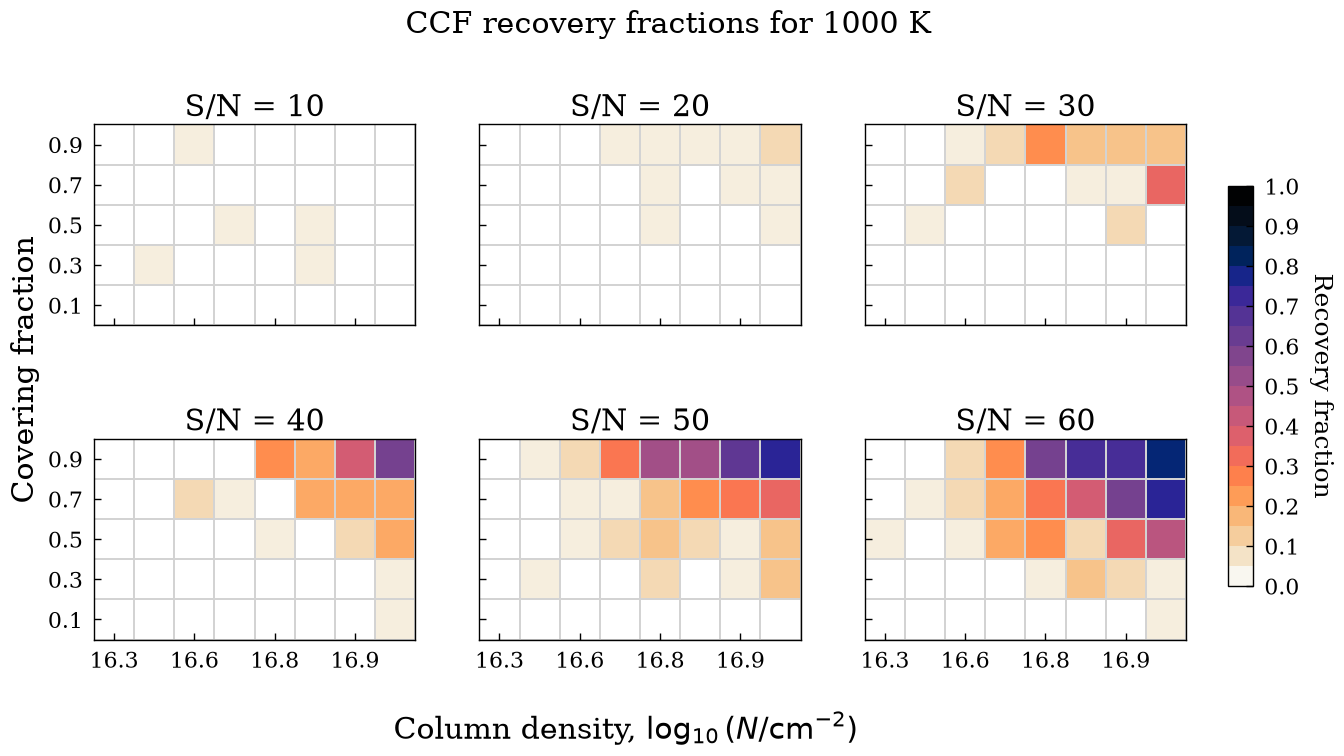

In [ ]:
import cmasher as cmr

recovery = (
    results_df
    .groupby(["temperature", "SNR", "cover_fraction", "column_density"])["recovered"]
    .mean()
    .rename("recovery_fraction")
    .reset_index()
)

temp_data = recovery[recovery["temperature"] == chosen_temp]
snrs = sorted(temp_data["SNR"].unique())

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8),
    sharex=True,
    sharey=True
)
axes = axes.ravel()
im = None

for ax, snr in zip(axes, snrs):
    subset = temp_data[temp_data["SNR"] == snr]

    heatmap_data = (
        subset.pivot(
            index="cover_fraction",
            columns="column_density",
            values="recovery_fraction"
        )
        .sort_index()
        .sort_index(axis=1)
    )

    values = heatmap_data.to_numpy()
    n_y, n_x = values.shape

    # Equal-sized cells, centred on each sampled parameter value
    x_edges = np.arange(n_x + 1) - 0.5
    y_edges = np.arange(n_y + 1) - 0.5

    im = ax.pcolormesh(
        x_edges,
        y_edges,
        values,
        cmap=cmr.torch_r,
        vmin=0,
        vmax=1,
        shading="flat",
        edgecolors="lightgrey",
        linewidth=1.2,
    )

    # Use only the exponents to keep the tick labels compact
    ax.set_xticks(np.arange(0, n_x, 2))
    ax.set_xticklabels([
        f"{np.log10(N):.1f}" for N in heatmap_data.columns[::2]
    ])

    ax.set_yticks(np.arange(n_y))
    ax.set_yticklabels([
        f"{cf:g}" for cf in heatmap_data.index
    ])

    ax.set_title(f"S/N = {snr}")
    ax.set_aspect("equal")
    ax.grid(False)
    ax.minorticks_off()

# Hide unused panels
for ax in axes[len(snrs):]:
    ax.set_visible(False)

# One shared label for each axis
fig.supxlabel(r"Column density, $\log_{10}(N/\mathrm{cm}^{-2})$",
            x=0.47, y=0.05)

fig.supylabel("Covering fraction", x=0.03, y=0.52)

fig.suptitle(f"CCF recovery fractions for {chosen_temp} K", y=0.97)

# Leave room for the shared labels and colour bar
fig.subplots_adjust(
    left=0.09,
    right=0.87,
    bottom=0.13,
    top=0.88,
    wspace=0.20,
    hspace=0.1
)

cbar_ax = fig.add_axes([0.90, 0.25, 0.018, 0.50])
cbar = fig.colorbar(im, cax=cbar_ax, ticks=np.arange(0, 1.01, 0.1), boundaries=np.linspace(0, 1, 21),)
cbar.set_label("Recovery fraction", rotation=270, labelpad=25)

plt.show()